# WeVisOne-VL: Object-level perception pipeline

Run **one image** through the complete object-level sequence: open-vocabulary detection → referring expression comprehension → box counting → point counting → pointing. The same model instance and the same input image are reused throughout.

## 1. Load the released model

Set `WEVISONE_MODEL` to override the checkpoint. Otherwise this notebook uses the repository-local release checkpoint when available, then falls back to the public model ID.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

from wevisone_vl import WeVisOneVL
from wevisone_vl.visualization import render_overlay, save_result


def find_repo_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "wevisone_vl").is_dir() and (candidate / "demo").is_dir():
            return candidate
    raise RuntimeError("Run this notebook from inside the WeVisOne-VL repository.")


repo_root = find_repo_root()
examples_dir = repo_root / "demo" / "examples"
local_checkpoint = repo_root / "checkpoints" / "WeVisOne-VL-4B"
model_path = os.environ.get("WEVISONE_MODEL") or (
    str(local_checkpoint) if local_checkpoint.is_dir() else "tencent/WeVisOne-VL-4B"
)
print(f"Loading WeVisOne-VL from: {model_path}")

model = WeVisOneVL(
    model_path,
    backend="transformers",
    device="auto",
    dtype="bfloat16",
)

Loading WeVisOne-VL from: checkpoints/WeVisOne-VL-4B


Loading weights:   0%|                                 | 0/714 [00:00<?, ?it/s]

Loading weights:   2%|▍                      | 12/714 [00:00<00:05, 119.97it/s]

Loading weights:   5%|█▏                     | 37/714 [00:00<00:03, 174.16it/s]

Loading weights:   9%|██▏                    | 67/714 [00:00<00:02, 224.08it/s]

...

Loading weights:  45%|█████████▉            | 323/714 [00:01<00:01, 301.05it/s]

Loading weights:  50%|██████████▉           | 355/714 [00:01<00:01, 261.04it/s]

Loading weights:  54%|███████████▊          | 383/714 [00:01<00:01, 237.80it/s]

Loading weights:  89%|███████████████████▌  | 635/714 [00:01<00:00, 785.26it/s]

Loading weights: 100%|██████████████████████| 714/714 [00:01<00:00, 431.77it/s]

## 2. Load one shared image

Image: demo/examples/images/dogs.jpg | size=(1024, 696)


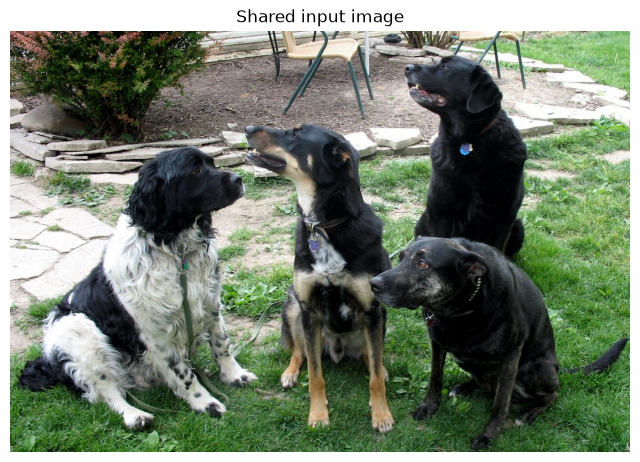

In [2]:
image_path = examples_dir / "images" / "dogs.jpg"
image = Image.open(image_path).convert("RGB")
print(f"Image: {image_path} | size={image.size}")

plt.figure(figsize=(8, 8))
plt.imshow(image)
plt.axis("off")
plt.title("Shared input image")
plt.show()

In [3]:
output_root = repo_root / "outputs" / "object_level_pipeline"


def show_prediction(title, result, output_name):
    paths = save_result(output_root / output_name, image, result)
    visualization = render_overlay(image, result)
    print("Prompt:", result.prompt)
    print("Raw response:", result.response)
    print(f"Latency: {result.latency_s:.2f}s")
    print("Saved overlay:", paths["overlay"])
    plt.figure(figsize=(8, 8))
    plt.imshow(visualization)
    plt.axis("off")
    plt.title(title)
    plt.show()
    return paths

## 3. Detection

Locate all instances of several open-vocabulary categories.

Prompt: Locate all the instances that match the following description: dog. chair. bush.
Raw response: <ref>dog</ref><box><13><274><399><949>,<379><222><620><954>,<581><489><996><997>,<637><61><834><539></box>, <ref>chair</ref><box><416><0><586><208>,<708><0><832><139></box>, <ref>bush</ref><box><0><0><327><259></box>
Latency: 4.07s
Saved overlay: outputs/object_level_pipeline/01_detection/overlay.png


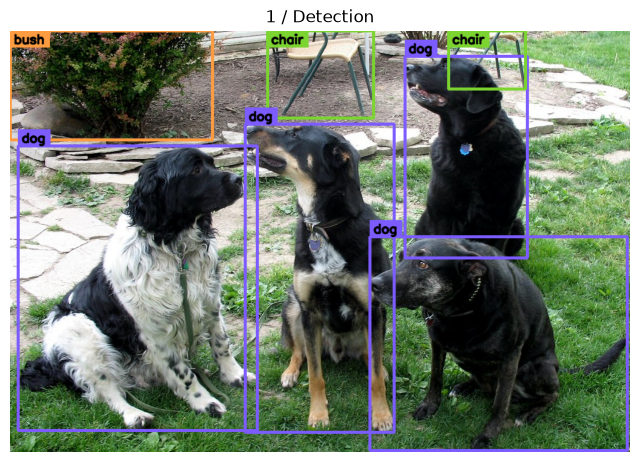

In [4]:
detection_result = model.predict(
    image,
    task="detection",
    query=["dog", "chair", "bush"],
    max_new_tokens=4096,
    temperature=0.0,
)
detection_paths = show_prediction("1 / Detection", detection_result, "01_detection")

## 4. Referring

Ground a natural-language description of one specific object in the same image.

Prompt: Locate the instances that match the following description: the black and white dog.
Raw response: <ref>the black and white dog</ref><box><13><274><398><948></box>
Latency: 0.57s
Saved overlay: outputs/object_level_pipeline/02_referring/overlay.png


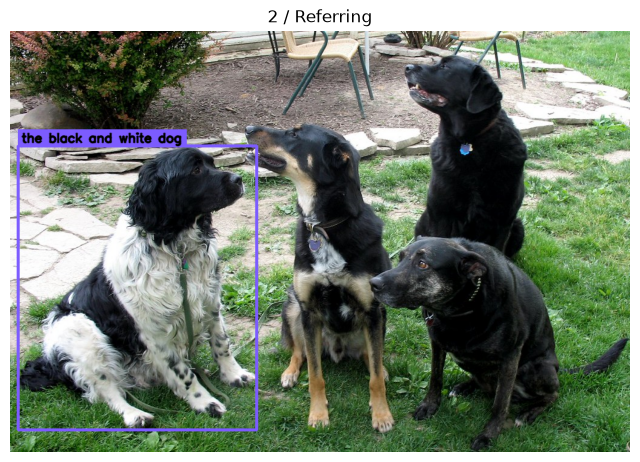

In [5]:
referring_result = model.predict(
    image,
    task="referring",
    query="the black and white dog",
    max_new_tokens=4096,
    temperature=0.0,
)
referring_paths = show_prediction("2 / Referring", referring_result, "02_referring")

## 5. Counting with boxes

Count the dogs and return a box for every counted instance.

Prompt: How many dogs in the image? Please count them with boxes.
Raw response: <ref>dogs</ref><box><12><272><400><949>,<378><221><620><954>,<580><487><998><999>,<637><60><834><541></box>
Total number: 4.
Latency: 1.03s
Saved overlay: outputs/object_level_pipeline/03_count_box/overlay.png


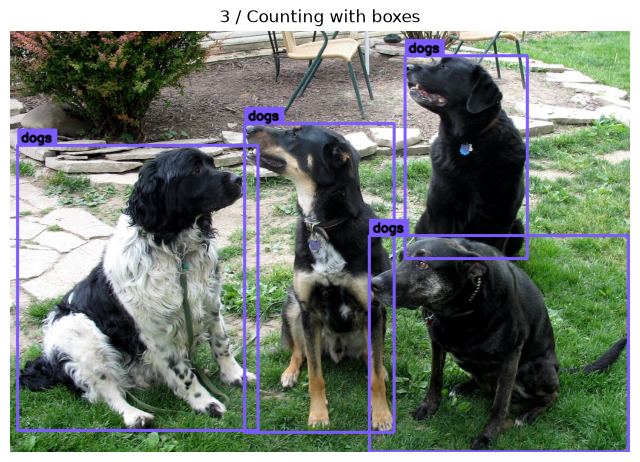

In [6]:
count_box_result = model.predict(
    image,
    task="count_box",
    query="dogs",
    max_new_tokens=4096,
    temperature=0.0,
)
count_box_paths = show_prediction("3 / Counting with boxes", count_box_result, "03_count_box")

## 6. Counting with points

Count the same target category again, this time using one point per instance.

Prompt: How many dogs in the image?
Raw response: <ref>dogs</ref><point><204><612>,<500><587>,<737><292>,<789><744></point>
Total number: 4.
Latency: 0.94s
Saved overlay: outputs/object_level_pipeline/04_count_point/overlay.png


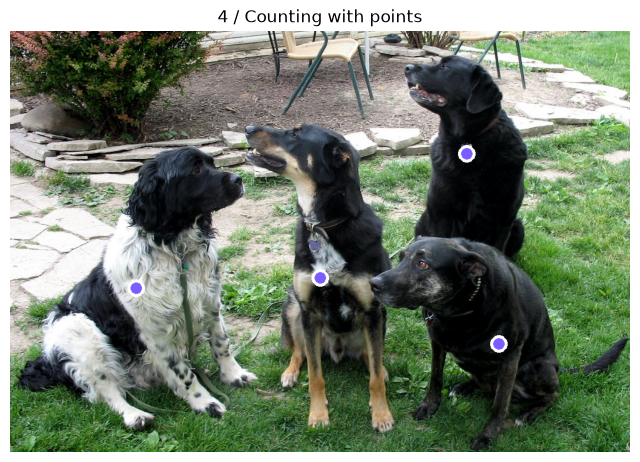

In [7]:
count_point_result = model.predict(
    image,
    task="count_point",
    query="dogs",
    max_new_tokens=4096,
    temperature=0.0,
)
count_point_paths = show_prediction("4 / Counting with points", count_point_result, "04_count_point")

## 7. Pointing

Return click-ready 2D locations for all dogs in the same image.

Prompt: point to: dogs
Raw response: <ref>dogs</ref><point><204><612>,<500><587>,<789><726>,<739><295></point>
Latency: 0.67s
Saved overlay: outputs/object_level_pipeline/05_pointing/overlay.png


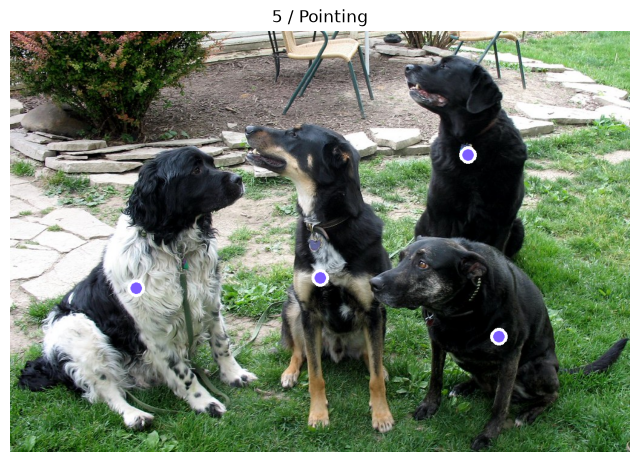

In [8]:
pointing_result = model.predict(
    image,
    task="point",
    query="dogs",
    max_new_tokens=4096,
    temperature=0.0,
)
pointing_paths = show_prediction("5 / Pointing", pointing_result, "05_pointing")